# ECG Project — 03. Signal quality, preprocessing and EDA

Цель: аудит качества, визуализация сигналов и подготовка обоснованного preprocessing до обучения моделей. Ноутбук не скачивает датасеты, не изменяет исходные файлы и не удаляет записи автоматически.

Принципы:
- Raw данные остаются неизменными.
- Сначала смотрим на сигналы и метки, затем выбираем фильтры.
- Нормализацию и любые параметры, оцениваемые по всей выборке, обучаем только на train.
- Все окна одного пациента должны попадать только в один split.
- Записи с несколькими диагнозами сохраняем как multi-label, не назначаем им произвольный единственный класс.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import os, json, ast, warnings
from collections import Counter
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path('/content/drive/MyDrive/ECG_detection')
RAW_ROOT = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_ROOT = PROJECT_ROOT / 'data' / 'processed'
REPORTS_ROOT = PROJECT_ROOT / 'reports'
FIGURES_ROOT = REPORTS_ROOT / 'figures'
for p in [PROCESSED_ROOT, REPORTS_ROOT, FIGURES_ROOT]:
    p.mkdir(parents=True, exist_ok=True)
print('Project exists:', PROJECT_ROOT.exists())
print('Raw data exists:', RAW_ROOT.exists())
print('Raw root:', RAW_ROOT)

Project exists: True
Raw data exists: True
Raw root: /content/drive/MyDrive/ECG_detection/data/raw


## 1. Инвентаризация реальных каталогов
Папки могут называться `chapman`, `chapman_shaoxing`, `ptbxl`, `mitbih` и т. п.; сначала проверяем фактические имена.

In [3]:
if RAW_ROOT.exists():
    dirs = sorted(p for p in RAW_ROOT.iterdir() if p.is_dir())
    display(pd.DataFrame([{
        'folder': p.name, 'path': str(p),
        'files': sum(1 for x in p.rglob('*') if x.is_file()),
        '.hea': sum(1 for x in p.rglob('*.hea')),
        '.mat': sum(1 for x in p.rglob('*.mat')),
        '.dat': sum(1 for x in p.rglob('*.dat')),
        '.csv': sum(1 for x in p.rglob('*.csv')),
    } for p in dirs]))
else:
    print('Путь RAW_ROOT не найден — проверь имя папки в Drive.')

,folder,path,files,.hea,.mat,.dat,.csv
0,chapman,/content/drive/MyDrive/ECG_detection/data/raw/...,91261,45152,45152,0,1
1,incart,/content/drive/MyDrive/ECG_detection/data/raw/...,233,75,0,75,0
2,mitbih,/content/drive/MyDrive/ECG_detection/data/raw/...,678,71,0,71,0
3,ptbxl,/content/drive/MyDrive/ECG_detection/data/raw/...,87252,43598,0,43598,2


## 2. Установка библиотек

In [4]:
%pip -q install wfdb scipy seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 5.5 MB/s eta 0:00:00


In [5]:
import wfdb
import scipy.signal as sps
import seaborn as sns
print('wfdb:', wfdb.__version__)

wfdb: 4.3.1


## 3. Поиск метаданных Chapman и PTB-XL

In [6]:
def find_dataset_dir(tokens):
    if not RAW_ROOT.exists(): return None
    return next((p for p in RAW_ROOT.iterdir() if p.is_dir() and any(t in p.name.lower() for t in tokens)), None)

def find_file(root, filename):
    if root is None or not root.exists(): return None
    matches = list(root.rglob(filename))
    return matches[0] if matches else None

chapman_root = find_dataset_dir(['chapman', 'shaoxing', 'ecg-arrhythmia'])
ptbxl_root = find_dataset_dir(['ptbxl', 'ptb-xl'])
ptb_meta_path = find_file(ptbxl_root, 'ptbxl_database.csv')
ptb_scp_path = find_file(ptbxl_root, 'scp_statements.csv')
print('Chapman:', chapman_root)
print('PTB-XL:', ptbxl_root)
print('PTB metadata:', ptb_meta_path)
print('PTB SCP statements:', ptb_scp_path)

Chapman: /content/drive/MyDrive/ECG_detection/data/raw/chapman
PTB-XL: /content/drive/MyDrive/ECG_detection/data/raw/ptbxl
PTB metadata: /content/drive/MyDrive/ECG_detection/data/raw/ptbxl/physionet.org/files/ptb-xl/1.0.3/ptbxl_database.csv
PTB SCP statements: /content/drive/MyDrive/ECG_detection/data/raw/ptbxl/physionet.org/files/ptb-xl/1.0.3/scp_statements.csv


In [7]:
ptbxl = pd.read_csv(ptb_meta_path) if ptb_meta_path else None
scp_statements = pd.read_csv(ptb_scp_path, index_col=0) if ptb_scp_path else None
if ptbxl is not None:
    print('PTB-XL shape:', ptbxl.shape)
    display(ptbxl.head(3))
    display((ptbxl.isna().mean().mul(100).sort_values(ascending=False).head(20)
             .rename('missing_pct').to_frame()))
    if 'ecg_id' in ptbxl: print('Duplicate ecg_id:', ptbxl['ecg_id'].duplicated().sum())
    if 'patient_id' in ptbxl: print('Unique patients:', ptbxl['patient_id'].nunique())
    if 'strat_fold' in ptbxl:
        display(ptbxl['strat_fold'].value_counts().sort_index().rename('records').to_frame())
else:
    print('PTB-XL metadata not found; check the directory name/path.')

PTB-XL shape: (21799, 28)


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr


,missing_pct
electrodes_problems,99.862379
infarction_stadium2,99.527501
pacemaker,98.665076
burst_noise,97.187944
baseline_drift,92.669389
extra_beats,91.059223
static_noise,85.045186
infarction_stadium1,74.255700
height,68.007707
weight,56.782421


Duplicate ecg_id: 0
Unique patients: 18869


,records
strat_fold,
1,2175
2,2181
3,2192
4,2174
5,2174
6,2173
7,2176
8,2173
9,2183


## 4. Визуализация распределения диагнозов PTB-XL

`scp_codes` содержит словарь кодов на одну запись. Одна ЭКГ может иметь несколько меток, поэтому сумма по классам закономерно может превышать число записей.

,SCP_code,records
0,SR,16748
1,NORM,9514
2,ABQRS,3327
3,IMI,2676
4,ASMI,2357
5,LVH,2132
6,NDT,1825
7,LAFB,1623
8,AFIB,1514
9,ISC_,1272


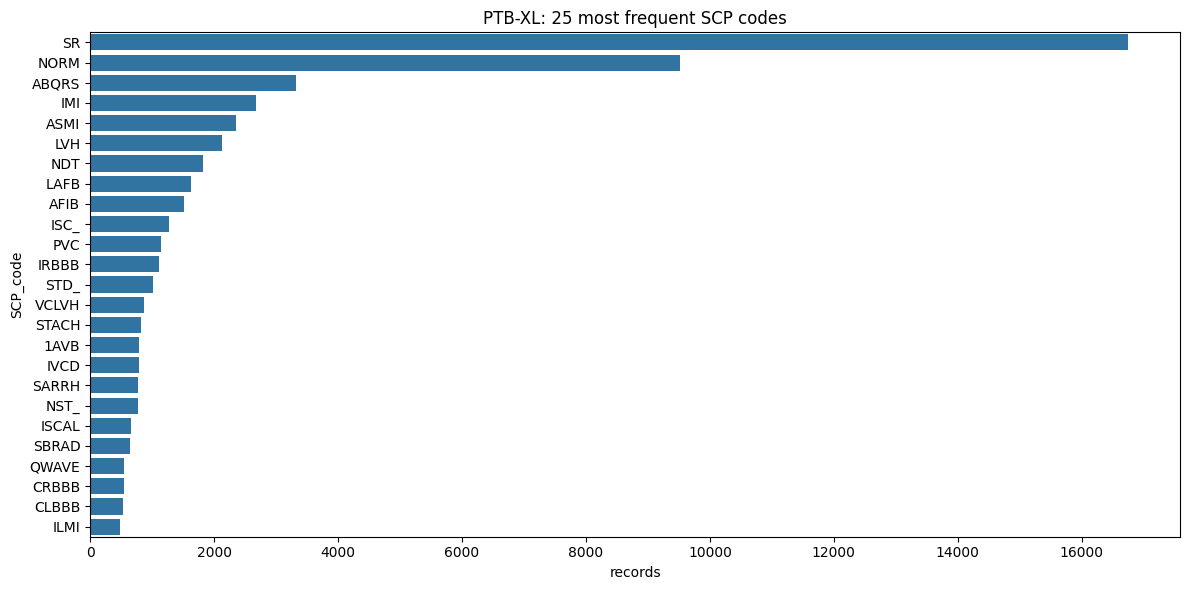

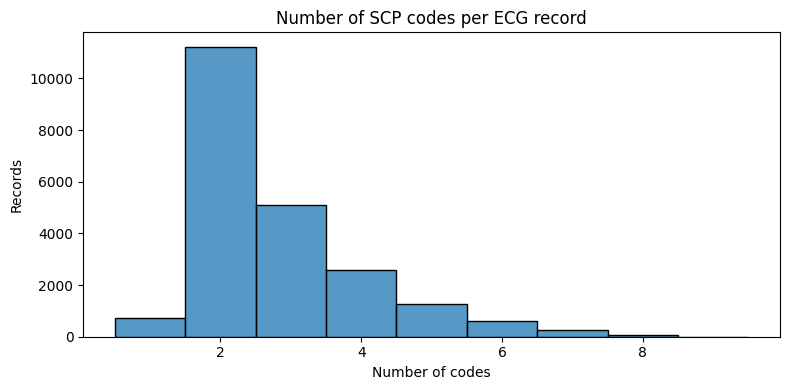

In [8]:
def parse_code_dict(x):
    if isinstance(x, dict): return x
    if pd.isna(x): return {}
    try:
        v = ast.literal_eval(x)
        return v if isinstance(v, dict) else {}
    except Exception:
        return {}

if ptbxl is not None and 'scp_codes' in ptbxl:
    code_counts = Counter()
    codes_per_record = []
    for x in ptbxl['scp_codes']:
        d = parse_code_dict(x)
        code_counts.update(d.keys())
        codes_per_record.append(len(d))
    top_codes = pd.DataFrame(code_counts.most_common(25), columns=['SCP_code','records'])
    display(top_codes)
    plt.figure(figsize=(12,6))
    sns.barplot(data=top_codes, x='records', y='SCP_code')
    plt.title('PTB-XL: 25 most frequent SCP codes')
    plt.tight_layout()
    plt.savefig(FIGURES_ROOT/'ptbxl_top_scp_codes.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.figure(figsize=(8,4))
    sns.histplot(codes_per_record, discrete=True)
    plt.title('Number of SCP codes per ECG record')
    plt.xlabel('Number of codes')
    plt.ylabel('Records')
    plt.tight_layout()
    plt.savefig(FIGURES_ROOT/'ptbxl_codes_per_record.png', dpi=160, bbox_inches='tight')
    plt.show()
else:
    print('PTB-XL scp_codes not available.')

## 5. Чтение и визуализация нескольких WFDB-сигналов

Читаем только несколько записей для контроля, не загружаем весь датасет в RAM.

Chapman examples: 12 | PTB-XL examples: 12


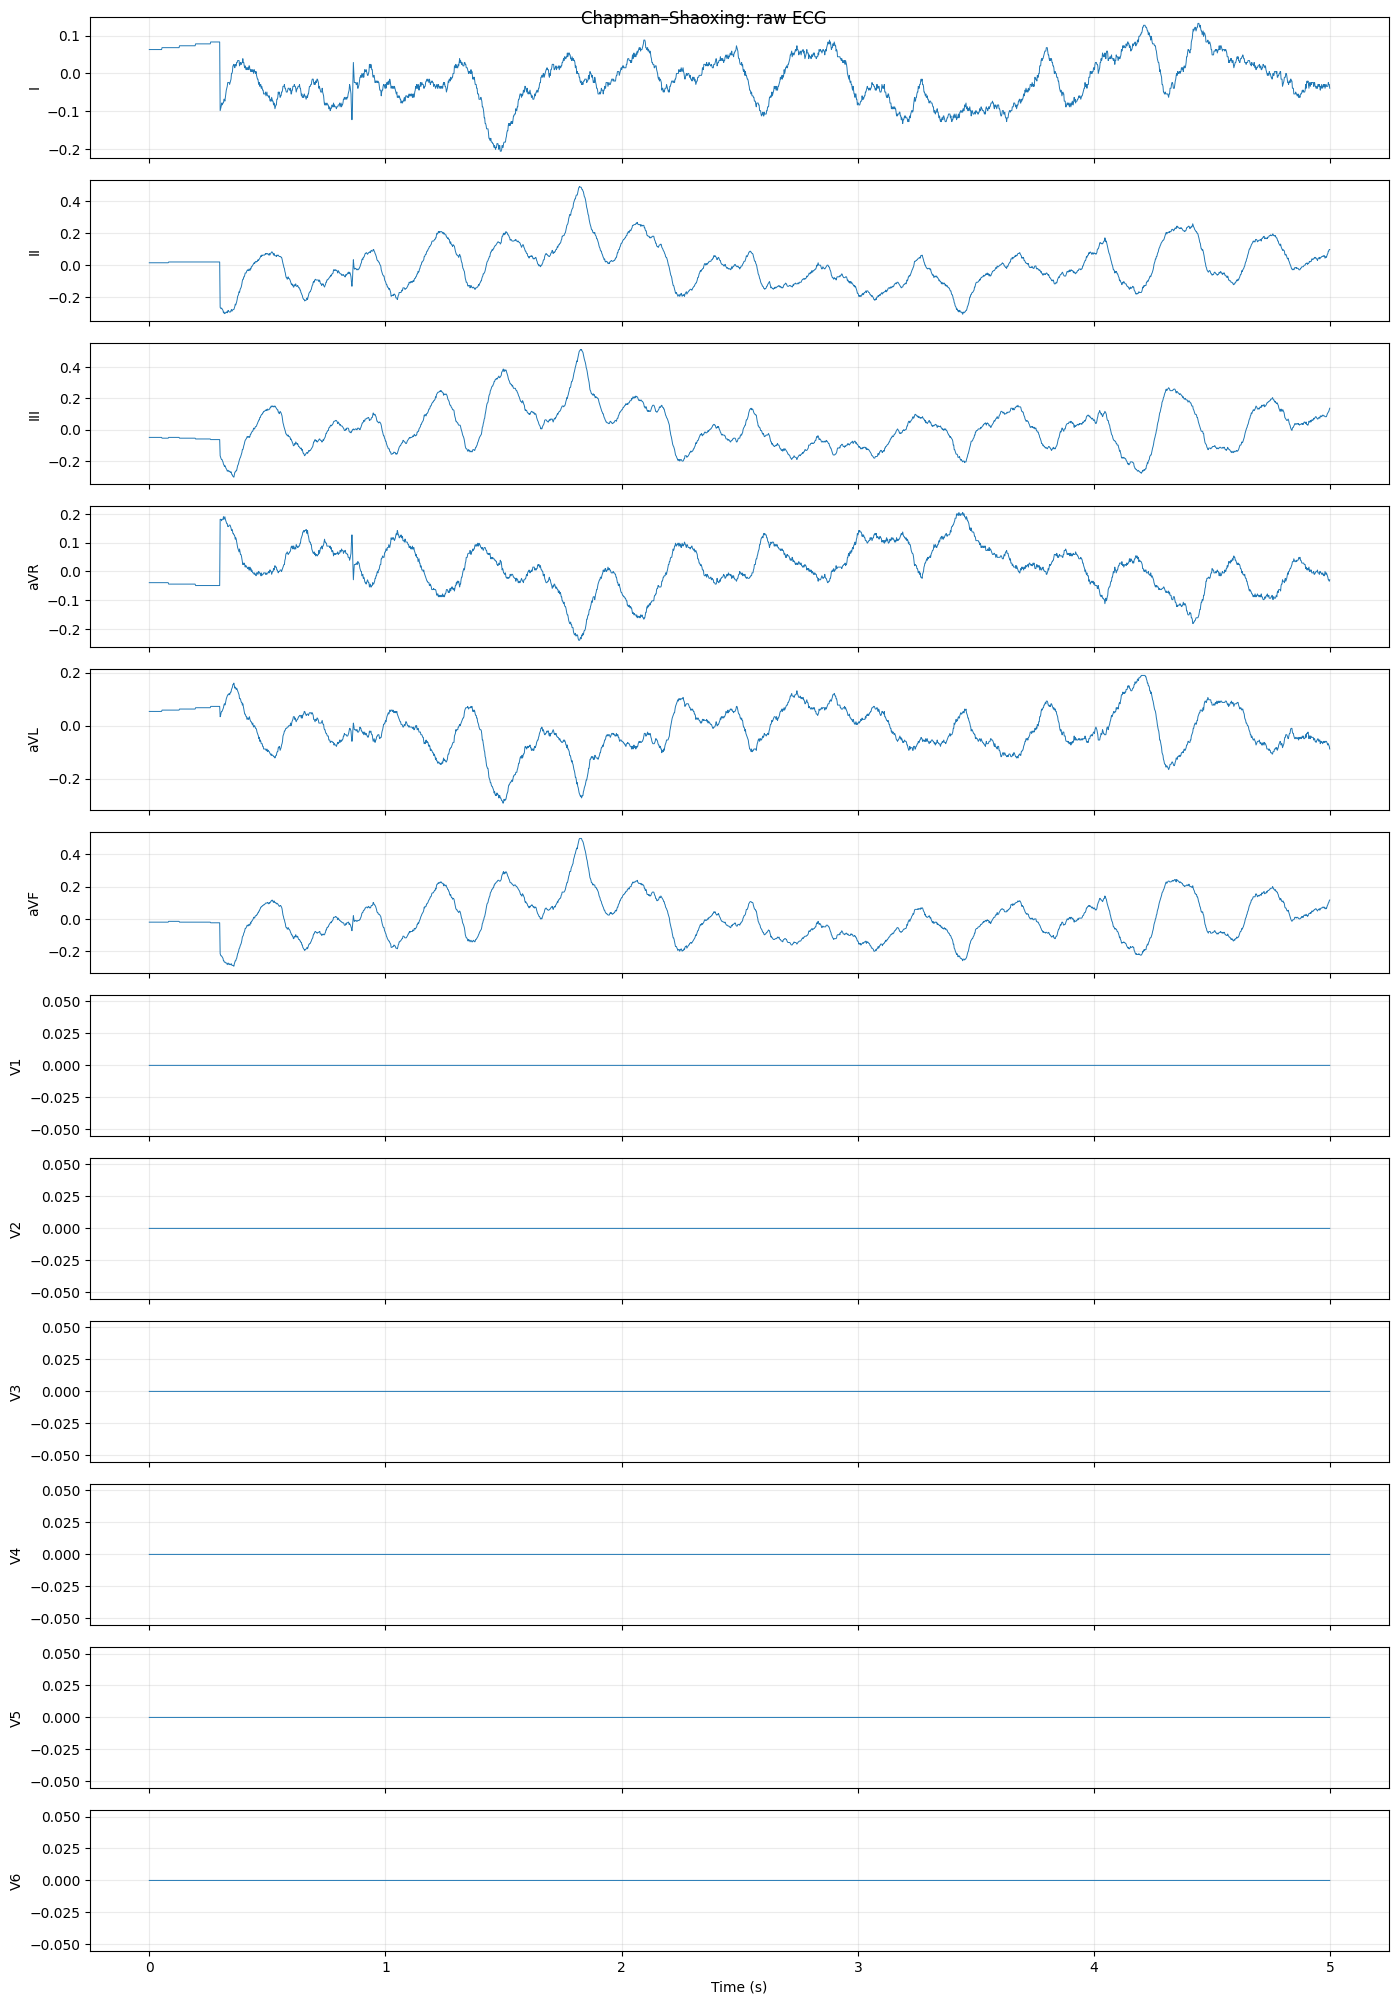

In [9]:
def list_wfdb_records(root, limit=12):
    if root is None or not root.exists(): return []
    return [p.with_suffix('') for p in list(root.rglob('*.hea'))[:limit]]

chapman_records = list_wfdb_records(chapman_root)
ptb_records = list_wfdb_records(ptbxl_root)
print('Chapman examples:', len(chapman_records), '| PTB-XL examples:', len(ptb_records))

def plot_wfdb_record(record_path, seconds=5, title=None):
    sig, fields = wfdb.rdsamp(str(record_path))
    fs = float(fields['fs'])
    n = min(len(sig), int(seconds*fs))
    sig = sig[:n]
    names = fields.get('sig_name') or [f'Lead {i+1}' for i in range(sig.shape[1])]
    fig, axes = plt.subplots(sig.shape[1], 1, figsize=(14, max(3, 1.7*sig.shape[1])), sharex=True)
    if sig.shape[1] == 1: axes = [axes]
    t = np.arange(n)/fs
    for i, ax in enumerate(axes):
        ax.plot(t, sig[:,i], linewidth=0.7)
        ax.set_ylabel(names[i] if i < len(names) else f'Lead {i+1}')
        ax.grid(alpha=.25)
    axes[-1].set_xlabel('Time (s)')
    fig.suptitle(title or Path(str(record_path)).name)
    plt.tight_layout()
    plt.show()
    return sig, fs, fields

if chapman_records:
    example_signal, example_fs, example_fields = plot_wfdb_record(chapman_records[0], title='Chapman–Shaoxing: raw ECG')
elif ptb_records:
    example_signal, example_fs, example_fields = plot_wfdb_record(ptb_records[0], title='PTB-XL: raw ECG')
else:
    example_signal = example_fs = example_fields = None
    print('WFDB .hea files not found. Dataset format needs manual inspection.')

## 6. Базовые QC-признаки сигнала

NaN/Inf, почти постоянные участки и robust amplitude range — только диагностические флаги. Не удаляем записи автоматически: пороги зависят от единиц измерения, усиления и устройства.

In [10]:
def signal_qc(sig, fs):
    x = np.asarray(sig, dtype=float)
    finite = np.isfinite(x)
    xf = x[finite]
    if xf.size:
        p01, med, p99 = np.percentile(xf, [1,50,99])
    else:
        p01 = med = p99 = np.nan
    flat = float(np.mean(np.abs(np.diff(x, axis=0)) < 1e-12)) if x.shape[0] > 1 else np.nan
    return {'samples': int(x.shape[0]), 'leads': int(x.shape[1]) if x.ndim>1 else 1,
            'fs_hz': float(fs), 'nonfinite_fraction': float(1-finite.mean()),
            'p01': float(p01), 'median': float(med), 'p99': float(p99),
            'robust_range_p99_p01': float(p99-p01), 'flat_difference_fraction': flat}

if example_signal is not None:
    display(pd.DataFrame([signal_qc(example_signal, example_fs)]))

,samples,leads,fs_hz,nonfinite_fraction,p01,median,p99,robust_range_p99_p01,flat_difference_fraction
0,2500,12,500.0,0.0,-0.215,0.0,0.239,0.454,0.659297


## 7. Raw vs filtered ECG — только демонстрация

Для иллюстрации применяется Butterworth band-pass 0.5–40 Hz с `sosfiltfilt`. Это не универсальное решение: низкая граница может менять ST-сегмент, а высокая — удалять детали. Поэтому сохраняем raw-сигнал и сначала визуально сравниваем. Notch 50 Hz добавлять только при подтверждённой сетевой помехе.

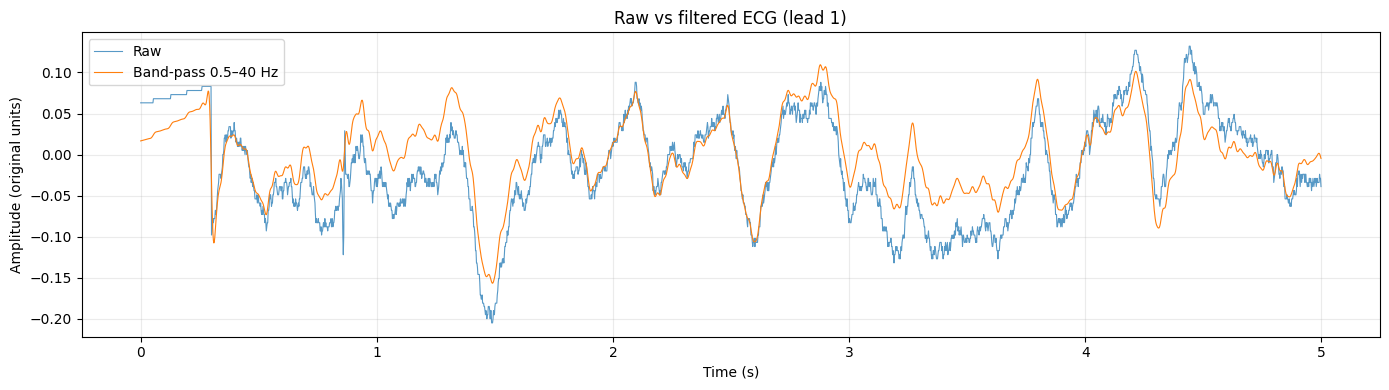

In [11]:
def filter_ecg_demo(sig, fs, low=0.5, high=40.0, order=4):
    x = np.asarray(sig, dtype=float)
    if not np.isfinite(x).all():
        raise ValueError('Signal contains NaN/Inf; inspect before filtering.')
    if not (0 < low < high < fs/2):
        raise ValueError(f'Invalid filter band for fs={fs} Hz.')
    sos = sps.butter(order, [low,high], btype='bandpass', fs=fs, output='sos')
    return sps.sosfiltfilt(sos, x, axis=0)

if example_signal is not None:
    filtered_signal = filter_ecg_demo(example_signal, example_fs)
    n = min(len(example_signal), int(5*example_fs))
    t = np.arange(n)/example_fs
    plt.figure(figsize=(14,4))
    plt.plot(t, example_signal[:n,0], label='Raw', linewidth=.8, alpha=.75)
    plt.plot(t, filtered_signal[:n,0], label='Band-pass 0.5–40 Hz', linewidth=.8)
    plt.title('Raw vs filtered ECG (lead 1)')
    plt.xlabel('Time (s)'); plt.ylabel('Amplitude (original units)')
    plt.legend(); plt.grid(alpha=.25); plt.tight_layout()
    plt.savefig(FIGURES_ROOT/'raw_vs_filtered_demo.png', dpi=160, bbox_inches='tight')
    plt.show()

## 8. Сравнение нормализации

Сравним два per-record подхода только для визуализации. Для модели отдельно проверим сохранение амплитудной информации. Если используем глобальную стандартизацию по каждому отведению, `mean/std` вычисляем только на train и применяем к validation/test без переоценки.

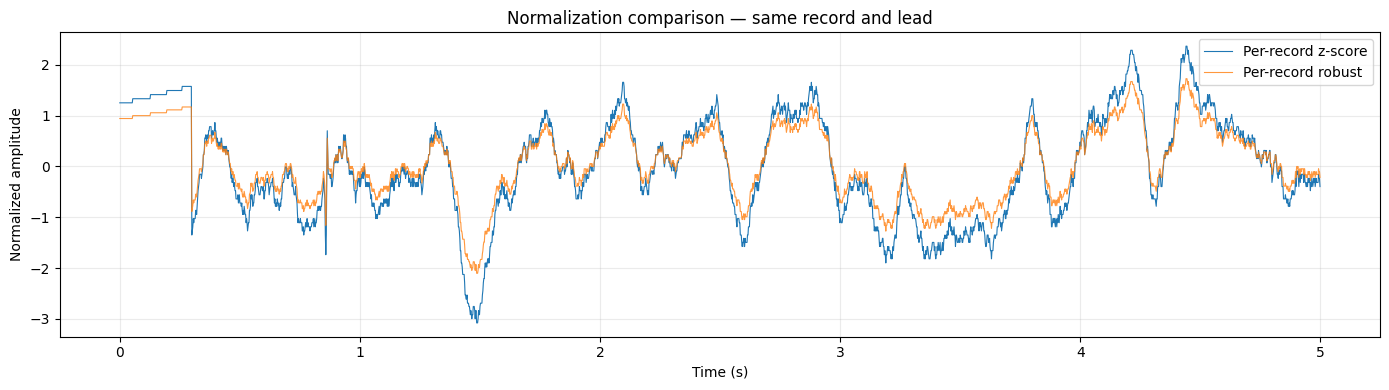

In [12]:
def normalize_per_record_zscore(x, eps=1e-8):
    x = np.asarray(x, dtype=np.float32)
    return (x-x.mean(axis=0,keepdims=True))/np.maximum(x.std(axis=0,keepdims=True),eps)

def normalize_per_record_robust(x, eps=1e-8):
    x = np.asarray(x, dtype=np.float32)
    med = np.median(x,axis=0,keepdims=True)
    q25 = np.percentile(x,25,axis=0,keepdims=True)
    q75 = np.percentile(x,75,axis=0,keepdims=True)
    return (x-med)/np.maximum(q75-q25,eps)

if example_signal is not None:
    n = min(len(example_signal), int(5*example_fs))
    z = normalize_per_record_zscore(example_signal[:n])
    r = normalize_per_record_robust(example_signal[:n])
    t = np.arange(n)/example_fs
    plt.figure(figsize=(14,4))
    plt.plot(t,z[:,0],label='Per-record z-score',linewidth=.8)
    plt.plot(t,r[:,0],label='Per-record robust',linewidth=.8,alpha=.8)
    plt.title('Normalization comparison — same record and lead')
    plt.xlabel('Time (s)'); plt.ylabel('Normalized amplitude')
    plt.legend(); plt.grid(alpha=.25); plt.tight_layout()
    plt.savefig(FIGURES_ROOT/'normalization_comparison_demo.png',dpi=160,bbox_inches='tight')
    plt.show()

## 9. Сохранение QC-отчёта

Отчёт содержит пути, метаданные и диагностические параметры, но не копирует сами сигналы.

In [13]:
qc_report = {
    'created_at_utc': datetime.utcnow().isoformat(timespec='seconds')+'Z',
    'project_root': str(PROJECT_ROOT),
    'raw_root_exists': RAW_ROOT.exists(),
    'chapman_root': str(chapman_root) if chapman_root else None,
    'ptbxl_root': str(ptbxl_root) if ptbxl_root else None,
    'ptbxl_metadata_shape': list(ptbxl.shape) if ptbxl is not None else None,
    'example_signal_qc': signal_qc(example_signal, example_fs) if example_signal is not None else None,
    'filter_demo': {'method':'Butterworth SOS band-pass','low_hz':0.5,'high_hz':40,'order':4,
                    'note':'Demonstration only; validate before batch processing.'},
    'normalization_candidates':['none','per-record z-score','per-record robust','train-only per-lead standardization'],
    'raw_data_modified': False
}
qc_path = REPORTS_ROOT/'signal_qc_eda_report.json'
with open(qc_path,'w',encoding='utf-8') as f:
    json.dump(qc_report,f,ensure_ascii=False,indent=2)
print('QC report:',qc_path)
print('Figures:',FIGURES_ROOT)

QC report: /content/drive/MyDrive/ECG_detection/reports/signal_qc_eda_report.json
Figures: /content/drive/MyDrive/ECG_detection/reports/figures


/tmp/ipykernel_4030/266326255.py:2: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  'created_at_utc': datetime.utcnow().isoformat(timespec='seconds')+'Z',


## 10. Решения перед пакетной обработкой

- [ ] Уточнить уровень задачи: запись, окно времени или отдельный beat.
- [ ] Проверить, отражают ли метки основную или все сопутствующие диагнозы.
- [ ] Согласовать число отведений и стратегию для отсутствующих отведений.
- [ ] Выбрать фильтрацию после сравнения raw/filtered и документировать параметры.
- [ ] Сравнить отсутствие нормализации, per-record z-score и robust scaling.
- [ ] Задать правила QC и сохранить число исключённых записей с причинами.
- [ ] Зафиксировать patient-level split до augmentation.
- [ ] Применять augmentation/синтетическую генерацию только к train.

**Следующий ноутбук:** `04_chapman_baseline_patient_split.ipynb` — проверенная таблица меток, разбиение по пациентам и воспроизведение baseline разработчика.